In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Lasso, LassoCV
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

In [45]:
data = pd.read_csv('data_2026.csv')

In [46]:
train = data.iloc[:200,:]
test = data.iloc[200:, :]

In [47]:
X_train = train.drop(columns='y')
y_train = train['y']

X_test = test.drop(columns='y')
y_test = test['y']

scaler = StandardScaler()
X_train = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

Exercise 1

Lasso

In [48]:
alphas = np.logspace(-4, 2, 100)

lasso_cv = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=100_000
).fit(X_train, y_train)

alpha = lasso_cv.alpha_
lasso_lambda = len(X_train) * alpha

print(f"sklearn alpha: {alpha}")
print(f"Equivalent course lambda: {lasso_lambda}")

sklearn alpha: 0.01
Equivalent course lambda: 2.0


In [49]:
# sklearn uses alpha = lambda / n in its normalized objective.
lasso = Lasso(
    alpha=lasso_lambda / len(X_train),
    max_iter=100_000
).fit(X_train, y_train)

PCR

In [50]:
pcr = make_pipeline(PCA(), LinearRegression())

search = GridSearchCV(
    pcr,
    {"pca__n_components": range(1, X_train.shape[1] + 1)},
    scoring="neg_mean_squared_error",
    cv=5
).fit(X_train, y_train)

k = search.best_params_["pca__n_components"]
print('Number of components for PCR:', k)

pcr = search.best_estimator_

Number of components for PCR: 79


In [51]:
pca_k = PCA(n_components=k).fit(X_train)
pca_10 = PCA(n_components=10).fit(X_train)
pca_9 = PCA(n_components=9).fit(X_train)
share = pca_k.explained_variance_ratio_.sum()
print(f'Explained variance by PCR with {k} components:', share)
print(f'Explained variance by PCR with 10 components:', pca_10.explained_variance_ratio_.sum())
print(f'Explained variance by PCR with 9 components:', pca_9.explained_variance_ratio_.sum())

Explained variance by PCR with 79 components: 0.999696988392451
Explained variance by PCR with 10 components: 0.9772420158194381
Explained variance by PCR with 9 components: 0.9359631054543122


Exercise 2

Outliers with residuals


In [52]:
lasso_residuals = y_train - lasso.predict(X_train)
pcr_residuals = y_train - pcr.predict(X_train)

residuals_df = pd.DataFrame({
    'Lasso': lasso_residuals,
    'PCR': pcr_residuals
    })

In [53]:
std_residuals = (residuals_df - residuals_df.mean(axis=0))/residuals_df.std(axis=0)

threshold = 2
lasso_outliers = np.where(np.abs(std_residuals['Lasso']) > threshold)[0]
pcr_outliers = np.where(np.abs(std_residuals['PCR']) > threshold)[0]

Outliers with clustering

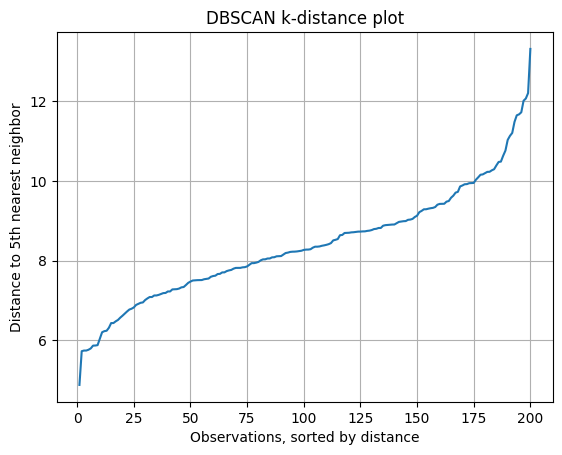

In [54]:
# min_samples=5 - distance to the 5th neighbor, including the point itself
nn = NearestNeighbors(n_neighbors=5).fit(X_train)
distances, _ = nn.kneighbors(X_train)
k_dist = sorted(distances[:, -1])

plt.plot(range(1, len(k_dist) + 1), k_dist)
plt.xlabel("Observations, sorted by distance")
plt.ylabel("Distance to 5th nearest neighbor")
plt.title("DBSCAN k-distance plot")
plt.grid(True)
plt.savefig('dbscan_k_distance.png', dpi=300, bbox_inches='tight')
plt.show()

In [55]:
for eps in [9.5, 10.0, 10.5, 11.0]:
    labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_train)
    n_noise = np.sum(labels == -1)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print("eps:", eps, ", clusters:", n_clusters, ", noise points:", n_noise)

eps: 9.5 , clusters: 1 , noise points: 10
eps: 10.0 , clusters: 1 , noise points: 6
eps: 10.5 , clusters: 1 , noise points: 5
eps: 11.0 , clusters: 1 , noise points: 4


Pick `eps = 10`

In [56]:
eps = 10
labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_train)
outlier_indices = np.flatnonzero(labels == -1)

In [57]:
print(f"Lasso outliers: {lasso_outliers}")
print(f"PCR outliers: {pcr_outliers}")
print(f"DBSCAN outliers: {outlier_indices}")

Lasso outliers: [ 50 103 127]
PCR outliers: [ 50 103 127]
DBSCAN outliers: [ 27  31  68 172 175 193]


Exercise 3

Removing the identified outliers

In [58]:
# Combine outlier indices from all detection methods
all_outlier_indices = np.unique(
    np.concatenate([lasso_outliers, pcr_outliers, outlier_indices])
)

data_cleaned = data.drop(index=all_outlier_indices)

X_train_cleaned = data_cleaned.iloc[:-100, :].drop(columns='y')
y_train_cleaned = data_cleaned.iloc[:-100, :]['y']

X_train_cleaned = pd.DataFrame(
    scaler.fit_transform(X_train_cleaned),
    columns=X_train_cleaned.columns,
    index=X_train_cleaned.index
)

# Scale the test set using the refitted training scaler
X_test_cleaned = pd.DataFrame(
    scaler.transform(test.drop(columns="y")),
    columns=test.drop(columns="y").columns,
    index=test.index
)

print(f"Removed {len(all_outlier_indices)} observations: {all_outlier_indices}")
print(f"New training shape: {X_train_cleaned.shape}")

Removed 9 observations: [ 27  31  50  68 103 127 172 175 193]
New training shape: (191, 100)


In [59]:
# Refit Lasso on the cleaned training data
lasso_cv_cleaned = LassoCV(
    alphas=alphas,
    cv=5,
    max_iter=100_000
).fit(X_train_cleaned, y_train_cleaned)

alpha_cleaned = lasso_cv_cleaned.alpha_
lasso_cleaned = Lasso(
    alpha=alpha_cleaned,
    max_iter=100_000
).fit(X_train_cleaned, y_train_cleaned)

# Refit PCR on the cleaned training data
pcr_search_cleaned = GridSearchCV(
    make_pipeline(PCA(), LinearRegression()),
    {"pca__n_components": range(1, X_train_cleaned.shape[1] + 1)},
    scoring="neg_mean_squared_error",
    cv=5
).fit(X_train_cleaned, y_train_cleaned)

pcr_cleaned = pcr_search_cleaned.best_estimator_
k_cleaned = pcr_search_cleaned.best_params_["pca__n_components"]

print(f"Cleaned Lasso alpha: {alpha_cleaned}")
print(f"Cleaned Lasso lambda: {len(X_train_cleaned) * alpha_cleaned}")
print(f"Cleaned PCR components: {k_cleaned}")

Cleaned Lasso alpha: 0.008697490026177835
Cleaned Lasso lambda: 1.6612205949999663
Cleaned PCR components: 95


Sequential heursitic

Lasso

In [68]:
alpha = 0.01
n = X_train.shape[0]
q = 3 # 3 observations removed each iteration
lasso = Lasso(alpha=alpha, max_iter=100_000)
X_train_k = X_train.copy()
y_train_k = y_train.copy()
lasso.fit(X_train_k, y_train_k)
residuals = np.zeros(y_train_k.shape[0])
keep_indices_k = None  # Initialize as an empty Series
obj_value_k = np.inf  # Initialize as infinity
i = 0
while True:
    print(f"Iteration {i + 1}")
    print(f"Current training shape: {X_train_k.shape}")
    residuals = y_train - lasso.predict(X_train)
    residuals_k = y_train_k - lasso.predict(X_train_k)
    squared_residuals = residuals ** 2

    keep_indices = squared_residuals.nsmallest(n-q).index
    print(f"Indices of the {q} largest residuals: {X_train.index.difference(keep_indices)}")
    obj_value = (
        np.sum(residuals_k**2) / (2 * y_train_k.shape[0])
        + alpha * np.sum(np.abs(lasso.coef_))
    )

    obj_improv = obj_value < obj_value_k

    if keep_indices_k is not None and np.array_equal(
        np.sort(keep_indices), np.sort(keep_indices_k)):
        print("Same observations removed as previous iteration. Stopping.")
        break
    elif not obj_improv:
        print("Objective value did not improve. Stopping.")
        break


    X_train_k = X_train.drop(index=X_train.index.difference(keep_indices), axis=0)
    y_train_k = y_train.drop(index=X_train.index.difference(keep_indices), axis=0)
    lasso.fit(X_train_k, y_train_k)
    keep_indices_k = keep_indices
    obj_value_k = obj_value
    i += 1

print(f"Final training shape after iterative removal: {X_train_k.shape}")
print(f"Removed observations: {X_train.index.difference(keep_indices_k)}")
    

Iteration 1
Current training shape: (200, 100)
Indices of the 3 largest residuals: Index([50, 103, 127], dtype='int64')
Iteration 2
Current training shape: (197, 100)
Indices of the 3 largest residuals: Index([50, 103, 127], dtype='int64')
Same observations removed as previous iteration. Stopping.
Final training shape after iterative removal: (197, 100)
Removed observations: Index([50, 103, 127], dtype='int64')


PCA

In [69]:
k = 79
q = 3
n = X_train.shape[0]
X_train_k = X_train.copy()
pca = PCA(n_components=k).fit(X_train)
Z = pca.transform(X_train)
X_hat = pca.inverse_transform(Z)
keep_indices_k = None # Initialize as an empty Series
i = 0
while True:
    print(f"Iteration {i + 1}")
    print(f"Current training shape: {X_train_k.shape}")
    projection_errors = ((X_train - X_hat) ** 2).sum(axis=1)
    keep_indices = projection_errors.nsmallest(n-q).index
    print(f"Indices of the {q} biggest projection errors: {X_train.index.difference(keep_indices)}")

    if keep_indices_k is not None and np.array_equal(
        np.sort(keep_indices), np.sort(keep_indices_k)):
        print("Same observations removed as previous iteration. Stopping.")
        break

    X_train_k = X_train.drop(index=X_train_k.index.difference(keep_indices), axis=0)
    pca = PCA(n_components=k).fit(X_train_k)
    Z = pca.transform(X_train)
    X_hat = pca.inverse_transform(Z)
    keep_indices_k = keep_indices
    i += 1

print(f"Final training shape after iterative removal: {X_train_k.shape}")
print(f"Removed observations: {X_train.index.difference(keep_indices_k)}")

Iteration 1
Current training shape: (200, 100)
Indices of the 3 biggest projection errors: Index([107, 113, 191], dtype='int64')
Iteration 2
Current training shape: (197, 100)
Indices of the 3 biggest projection errors: Index([107, 113, 191], dtype='int64')
Same observations removed as previous iteration. Stopping.
Final training shape after iterative removal: (197, 100)
Removed observations: Index([107, 113, 191], dtype='int64')
